In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, recall_score
from src.models.oee import calcular_oee_predito, PENALIDADES_OEE

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.float_format", lambda x: "%.4f" % x)

caminho_dados = ROOT_DIR / "data" / "processed" / "dados_sensores_tratados.csv"
df = pd.read_csv(caminho_dados)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(by="timestamp").reset_index(drop=True)

print(f"Base tratada carregada: {len(df)} registros.")

Base tratada carregada: 10000 registros.


In [2]:
# Split estritamente temporal (ordem cronológica para séries industriais)
split_idx = int(len(df) * 0.70)
df_train = df.iloc[:split_idx].copy()
df_test = df.iloc[split_idx:].copy()

print(f"Treino (70%): {df_train.shape[0]} amostras | {df_train['timestamp'].min()} -> {df_train['timestamp'].max()}")
print(f"Teste  (30%): {df_test.shape[0]} amostras | {df_test['timestamp'].min()} -> {df_test['timestamp'].max()}")

# Seleção de features descartando metadados e o alvo
colunas_excluir = ["timestamp", "id_celula", "liga_metalica", "tipo_falha"]
features = [col for col in df.columns if col not in colunas_excluir]

X_train = df_train[features]
y_train = df_train["tipo_falha"]
X_test = df_test[features]
y_test = df_test["tipo_falha"]

print(f"\nTotal de features preditivas: {len(features)}")
print("Distribuição de classes no Treino (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

Treino (70%): 7000 amostras | 2026-10-01 00:00:00 -> 2026-10-25 07:15:00
Teste  (30%): 3000 amostras | 2026-10-25 07:20:00 -> 2026-11-04 17:15:00

Total de features preditivas: 32
Distribuição de classes no Treino (%):
tipo_falha
0   85.6300
2    4.8700
1    4.8300
3    4.6700
Name: proportion, dtype: float64


In [3]:
# 1. Random Forest com ponderação de classes
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 2. HistGradientBoosting com ponderação de classes
hgb = HistGradientBoostingClassifier(
    class_weight="balanced",
    max_iter=150,
    learning_rate=0.08,
    random_state=42
)
hgb.fit(X_train, y_train)
y_pred_hgb = hgb.predict(X_test)

nomes_classes = [PENALIDADES_OEE[i]["descricao"] for i in range(4)]

print("=" * 60)
print("RELATÓRIO: RANDOM FOREST CLASSIFIER")
print("=" * 60)
print(classification_report(y_test, y_pred_rf, target_names=nomes_classes, digits=4))

print("=" * 60)
print("RELATÓRIO: HIST GRADIENT BOOSTING")
print("=" * 60)
print(classification_report(y_test, y_pred_hgb, target_names=nomes_classes, digits=4))

RELATÓRIO: RANDOM FOREST CLASSIFIER
                                            precision    recall  f1-score   support

                           Operação Normal     0.9996    1.0000    0.9998      2563
      Desgaste Severo de Ferramenta / Fuso     0.9847    0.9773    0.9810       132
      Obstrução no Sistema de Refrigeração     1.0000    0.9881    0.9940       168
Desalinhamento da Matriz / Trinca Mecânica     0.9784    0.9927    0.9855       137

                                  accuracy                         0.9980      3000
                                 macro avg     0.9907    0.9895    0.9901      3000
                              weighted avg     0.9980    0.9980    0.9980      3000

RELATÓRIO: HIST GRADIENT BOOSTING
                                            precision    recall  f1-score   support

                           Operação Normal     1.0000    1.0000    1.0000      2563
      Desgaste Severo de Ferramenta / Fuso     0.9847    0.9773    0.9810       132
  

--- Validação do Critério de Excelência (Recall >= 90%) ---
Classe 0 (Operação Normal): Recall = 100.00% -> APROVADO
Classe 1 (Desgaste Severo de Ferramenta / Fuso): Recall = 97.73% -> APROVADO
Classe 2 (Obstrução no Sistema de Refrigeração): Recall = 100.00% -> APROVADO
Classe 3 (Desalinhamento da Matriz / Trinca Mecânica): Recall = 98.54% -> APROVADO


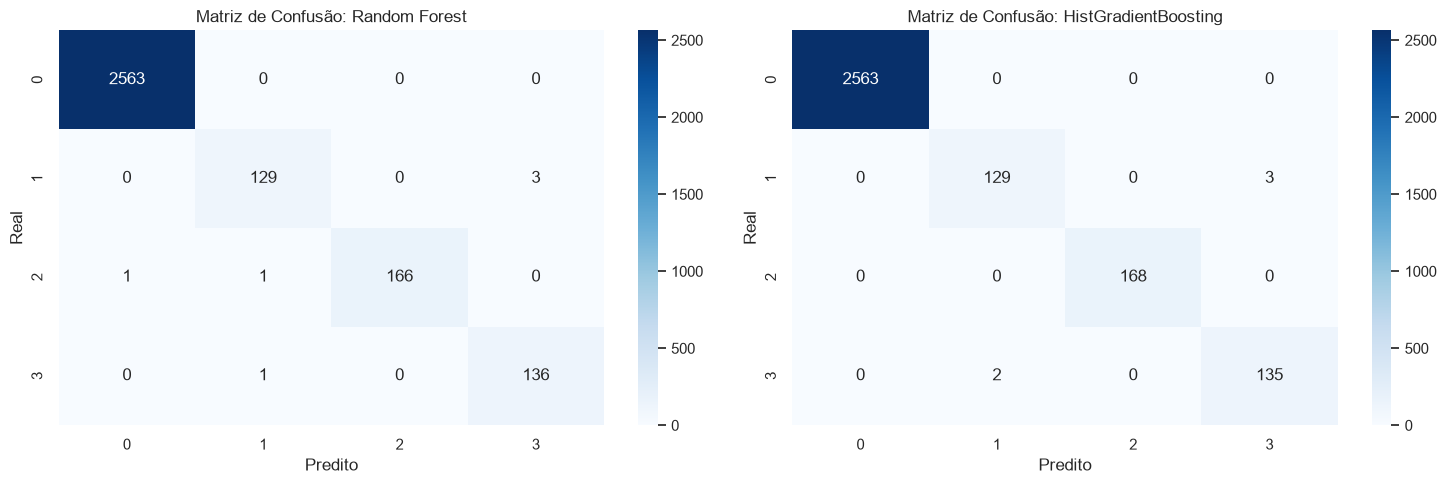

In [4]:
# Avaliação da exigência da rubrica de avaliação
recalls = recall_score(y_test, y_pred_hgb, average=None)
print("--- Validação do Critério de Excelência (Recall >= 90%) ---")
for i, r in enumerate(recalls):
    aprovado = "APROVADO" if r >= 0.90 else "REPROVADO"
    print(f"Classe {i} ({nomes_classes[i]}): Recall = {r * 100:.2f}% -> {aprovado}")

# Plotagem das Matrizes de Confusão
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, preds, tit in zip(axes, [y_pred_rf, y_pred_hgb], ["Random Forest", "HistGradientBoosting"]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(4), yticklabels=range(4), ax=ax)
    ax.set_title(f"Matriz de Confusão: {tit}")
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

In [5]:
# Aplica a regra de OEE sobre as previsões do modelo de teste
df_test_resultado = df_test.copy()
df_test_resultado["tipo_falha_predito"] = y_pred_hgb

df_oee = calcular_oee_predito(df_test_resultado, col_classe_predita="tipo_falha_predito")

resumo_oee = df_oee.groupby("id_celula")[["oee_disp", "oee_perf", "oee_qual", "oee_global"]].mean() * 100
print("--- OEE Médio Estimado por Célula no Conjunto de Teste (%) ---")
display(resumo_oee.round(2))

--- OEE Médio Estimado por Célula no Conjunto de Teste (%) ---


,oee_disp,oee_perf,oee_qual,oee_global
id_celula,,,,
CEL-201,94.2100,96.2000,94.5300,90.9000
CEL-202,94.4600,96.1600,94.2200,90.2700
CEL-203,95.0400,96.6700,94.8700,91.3600
CEL-204,95.1700,96.9800,95.2000,91.9300


In [6]:
#Exportação
caminho_model_dir = ROOT_DIR / "models"
caminho_model_dir.mkdir(parents=True, exist_ok=True)

caminho_modelo = caminho_model_dir / "modelo_preditivo_vulcantech.joblib"

artefato = {
    "model": hgb,
    "feature_names": features,
    "target_classes": PENALIDADES_OEE
}

joblib.dump(artefato, caminho_modelo)
print(f"Modelo salvo com sucesso em: {caminho_modelo.resolve()}")

Modelo salvo com sucesso em: C:\Users\henrique_schorck\Documents\GitHub\Projeto-Integrador-Vulcan\models\modelo_preditivo_vulcantech.joblib
